# Can you trust the instrument's spectrum? Process the raw data yourself

You'll turn the raw signal the instrument records into a spectrum, compare it with the instrument's
own, and decide whether you can trust the instrument's spectrum.

The spectrometer records a **free induction decay** (FID): signal against time. Here you process
the Ala-Ala FIDs from notebook 01 into spectra yourself, one step per cell.

Time: about 30 minutes. Do notebook 01 first. Boxes headed **RECORD YOUR ANSWER** are where you
write something; the reveal then shows what happened.

Data: Petkowski, M. D. Seager, Bains and S. Seager, Zenodo [10.5281/zenodo.11223995](https://doi.org/10.5281/zenodo.11223995), CC BY 4.0. Paper: *Scientific Reports* 14, 17083 (2024).

In [1]:
# Setup. In Colab this first installs the training package and the Rakiura helper (about 30 s).
import importlib.util

if importlib.util.find_spec("nmrtrain") is None:
    %pip install -q "nmrtrain @ git+https://github.com/Rakiura-Inc/morning-star-nmr@main"
if importlib.util.find_spec("rakiura") is None:
    %pip install -q "rakiura @ git+https://github.com/Rakiura-Inc/rakiura-py@main"
import matplotlib.pyplot as plt
import nmrglue as ng  # the standard Python library for reading and processing NMR data
import numpy as np
from scipy.signal import find_peaks

import nmrtrain as nt  # this course's plumbing: downloads, checks, your answers, the hand-in

NOTEBOOK = "notebooks/04_process_raw_fids.ipynb"
MODE = nt.portal.connect(NOTEBOOK)

Not connected to Rakiura. Your work stays on this computer. Run the Connect cell below to tick steps on Rakiura.


> **CONNECT TO RAKIURA (optional, recommended)**
>
> **What it does:** ticks your checklist on the step as you go and attaches your figures to it. Nothing is sent until you connect.
>
> **How:** run the cell below, open the link it prints, check the code matches the one printed here, and click Allow. In Colab you do this once per session. To skip the click, add your key as a Colab secret named `RAKIURA_KEY` (the key icon on the left; get the key in Rakiura under Settings > Notebook key).
>
> **Skipping it is fine:** your work is kept on this computer, and you can attach your files on the step page instead.

In [2]:
# Connect to Rakiura (optional). Open the link it prints, check the code matches, click Allow.
MODE = nt.portal.connect(NOTEBOOK, sign_in=True)

Not connected to Rakiura. Your work stays on this computer. Run this cell again to try once more, or attach your files on the step page.


In [3]:
# The raw signals behind notebook 01's Ala-Ala spectra in 98% acid, at 1 day and 4 months.
DIPEPTIDE_SPECTRA = "11223995"  # Zenodo record: Petkowski et al., CC BY 4.0
ala_ala_files = nt.data.fetch(DIPEPTIDE_SPECTRA, "Ala-Ala", acid="98%", times=["1day", "4Month"])
first_file = ala_ala_files[0]  # 1 day: you process this one step by step

# nmrglue reads the FID (fid) and the instrument's settings (dic) from the experiment folder.
dic, fid = ng.bruker.read(nt.io.experiment_folder(first_file))
sweep_width_hz = dic["acqus"]["SW_h"]  # the range of frequencies recorded
print(
    f"{nt.io.label_of(first_file)}: {fid.size} complex points, sweep width {sweep_width_hz:.0f} Hz"
)

AA 1H 98% w/w D2SO4: 2 spectra, all cached
Data: Petkowski, J. J.; Seager, M. D.; Bains, W.; Seager, S. (2024). General Instability of Dipeptides in Concentrated Sulfuric Acid as Relevant for the Venus Cloud Habitability (Supplementary dataset S1). Zenodo. https://doi.org/10.5281/zenodo.11223995 (CC BY 4.0). Paper: Petkowski et al. 2024, Scientific Reports 14, 17083, doi:10.1038/s41598-024-67342-w.
Ala-Ala in 98%, 1 day: 32768 complex points, sweep width 7812 Hz


The raw signal is a free induction decay (FID): the hydrogens ring after a radio pulse, and the
ringing dies away within a fraction of a second. Look for the wave shrinking from left to right,
and for the short flat start: that is the delay step 1 removes. Each peak in the spectrum is one
frequency mixed into this wave; step 4 separates them.

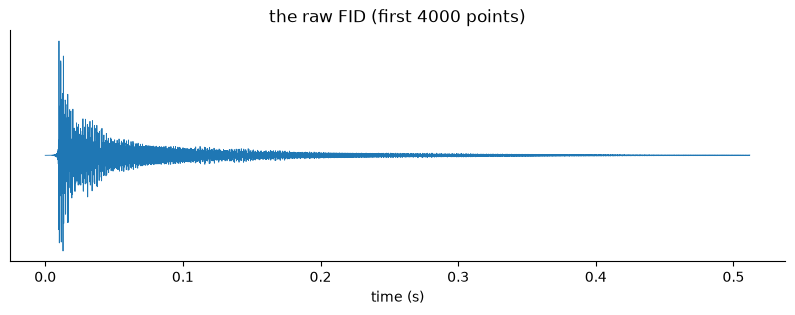

In [4]:
# The instrument records one point every 1 / sweep width seconds.
seconds = np.arange(4000) / sweep_width_hz
fig_fid, ax = plt.subplots(figsize=(10, 3))
ax.plot(seconds, fid.real[:4000], lw=0.6)  # .real: the FID is complex; this is its real part
ax.set_xlabel("time (s)")
ax.set_yticks([])  # the signal's size has no unit here
ax.set_title("the raw FID (first 4000 points)")
plt.show()

### What you need

The instrument made its own spectrum from this same raw signal, with the same steps you are about
to run, so a careful run of your own should match it.

These spectra come from a Bruker spectrometer. With its data, the Fourier transform (the step that
turns the signal over time into peaks by frequency) puts high and low ppm at opposite ends, so the
spectrum comes out mirrored. In 98% acid the acid peak sits near 11.5 ppm. Mirroring flips the axis
end to end around its middle, about 6 ppm on this scale.

> **RECORD YOUR ANSWER: predict before you process anything**
>
> **What gets saved:** `MY_PREDICTION`, two short answers, saved with the time.
>
> **Where to look:** the paragraph above, and the acid peak you found in notebook 01.
>
> **How to fill this in:**
> - `matches_instrument`: will your spectrum match the instrument's: `"yes"`, `"no"` or `"unsure"`
> - `acid_ppm_if_not_reversed`: where the acid peak lands, in ppm, if you skip reversing the axis (step 6 below), a number like `3.0`

<details><summary>Stuck? Open hint 1</summary>

How far is 11.5 ppm from the middle of the axis at about 6 ppm? Go the same distance on the other side.

</details>

<details><summary>Stuck? Open hint 2</summary>

11.5 is about 5.5 above 6, so the mirror image lands about 5.5 below 6, between 0.5 and 0.6 ppm.

</details>

In [5]:
MY_PREDICTION = {
    "matches_instrument": ...,  # "yes", "no" or "unsure"
    # a number in ppm: where the acid peak lands if you skip the reverse step
    "acid_ppm_if_not_reversed": ...,
}
nt.record.predict("raw", MY_PREDICTION)

Fill in at least one prediction above (replace the ...), then run this cell again.


## The steps

The next two cells run steps 1 to 5:

1. Remove the digital filter delay: the instrument's digital filter delays the start of the
   recording, and this step removes the delay.
2. Line broadening: multiply the signal by a decaying curve. That smooths the noise and widens each
   peak slightly. The instrument used 0.5 Hz, which widens each peak by about that much.
3. Zero fill: pad the recording with zeros, so the spectrum has more points and peaks come out
   smoother. It adds no information.
4. Fourier transform: turn the signal over time into peaks by frequency.
5. Phase: make every peak point up, with its two sides symmetric (automatic here).

In [6]:
# The steps follow nmrglue's own Bruker example (process_and_plot_nmrglue.py, BSD 3-Clause).
LINE_BROADENING_HZ = 0.5  # the instrument's own setting for these spectra

# Step 1: remove the delay the digital filter leaves at the start of the recording.
without_delay = ng.bruker.remove_digital_filter(dic, fid)
# Step 2: line broadening (em: exponential multiplication). nmrglue's em takes the
# broadening as a fraction of the sweep width, so divide the Hz by the sweep width in Hz.
broadened = ng.proc_base.em(without_delay, lb=LINE_BROADENING_HZ / float(sweep_width_hz))

In [7]:
# Step 3, used in the next cell and again in the reveal.
def zero_filled(recording, zero_fill):
    """The FID padded with zeros to zero_fill points. A size below the recording's has
    nothing to pad, so the recording is kept as it is, with one line saying so."""
    if zero_fill < recording.size:
        print(
            f"ZERO_FILL = {zero_fill} is smaller than the {recording.size} points in this "
            f"recording, so there is nothing to pad. Using {recording.size} points. "
            "Pick 32768 or more."
        )
        return recording
    return ng.proc_base.zf_size(recording, zero_fill)


# Step 5, used in the next cell and again in the reveal.
def phased(frequency_data):
    """Automatic phase correction with ACME (an entropy rule nmrglue offers), then the sign
    flipped if the peaks came out pointing down."""
    corrected = ng.proc_autophase.autops(frequency_data, "acme", disp=False)
    if abs(corrected.real.min()) > corrected.real.max():  # the deepest dip beats the top
        corrected = -corrected
    return corrected

### What you need

The recording has 32,768 points. Zero-filling pads it with zeros before the transform. That gives
more points per peak (a finer ppm grid), so peaks come out smoother. It adds no new information. The
instrument's own spectrum has 32,768 points, so it padded nothing.

> **RECORD YOUR ANSWER: choose the zero-fill**
>
> **What gets saved:** `ZERO_FILL`, the number of points after padding.
>
> **Where to look:** the overlay plots and the numbers in the reveal below, after you run it.
>
> **How to fill this in:**
> - Keep `65536` (twice the recording) for the first run.
> - Then try `32768`, the instrument's choice (no padding), and `131072`. Each time, run the cells down to the reveal again and compare the peak shapes and the largest line difference.

<details><summary>Stuck? Open hint 1</summary>

Run once with each value and look at the tops of the peaks in the reveal plots.

</details>

<details><summary>Stuck? Open hint 2</summary>

With fewer points, peaks look more jagged and their tops can fall between points. More points give a
finer grid but no new information. A value below 32768 has nothing to pad, so the notebook keeps the
recording as it is.

</details>

In [8]:
ZERO_FILL = 65536  # the number of points after padding: 65536, or try 32768 or 131072
nt.record.saved("ZERO_FILL", ZERO_FILL, "the number of points after zero-filling")

padded = zero_filled(broadened, ZERO_FILL)  # step 3
transformed = ng.proc_base.fft(padded)  # step 4: signal over time becomes peaks by frequency
phased_spectrum = phased(transformed)  # step 5

**Saved** `ZERO_FILL = 65536`: the number of points after zero-filling.

### Trap: the mirrored axis

The next cell checks your spectrum before the last steps. Compare where the acid peak lands with
your prediction.

Check the acid peak after every processing run; it catches a mirrored axis.

In [9]:
# The ppm of every point, from the instrument's settings, and the axis check.
udic = ng.bruker.guess_udic(dic, phased_spectrum)
ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()
not_reversed = nt.io.labelled(first_file, dic, ppm, phased_spectrum, processing="raw")
print(nt.checks.check_axis(not_reversed))

Trap: Ala-Ala in 98%, 1 day: the acid peak is at 0.57 ppm here. In 98% acid it sits near 11.5 ppm, so the ppm axis is probably reversed. Use ng.proc_base.rev or load the processed spectrum.


The next cell runs the last two steps and checks the axis again:

6. Reverse: with this instrument's data the transform puts high and low ppm at opposite ends; this
   step puts them back.
7. Baseline: subtract a smooth curve so the floor between peaks sits at zero.

In [10]:
# Step 7 written out, so you can see what a baseline correction does. nmrglue's
# proc_bl.baseline_corrector, listed under "Your own code", does the same job its own way.
def baseline_corrected(intensity, order=3, quietest_share=0.8):
    """The intensity minus a smooth curve (a polynomial of this order) fitted to the quietest
    80% of the points, the ones nearest the median, so the floor between peaks sits at zero."""
    position = np.linspace(-1, 1, intensity.size)  # each point's place, scaled to -1..1 for the fit
    distance_from_median = np.abs(intensity - np.median(intensity))
    cutoff = np.quantile(distance_from_median, quietest_share)
    quiet = distance_from_median <= cutoff  # True for the quietest 80% of the points
    coefficients = np.polynomial.polynomial.polyfit(position[quiet], intensity[quiet], order)
    return intensity - np.polynomial.polynomial.polyval(position, coefficients)

In [11]:
# Step 6: reverse, so high ppm sits at the start, as on the instrument's axis.
# The ppm axis runs high to low; rev turns the data round so it runs the same way.
reversed_spectrum = ng.proc_base.rev(phased_spectrum)
# Step 7: baseline, on the real part (the spectrum is complex; the real part is the one drawn).
intensity = baseline_corrected(reversed_spectrum.real)
mine = nt.io.labelled(first_file, dic, ppm, intensity, processing="raw")
print(nt.checks.check_axis(mine))

OK: Ala-Ala in 98%, 1 day: acid peak at 11.434 ppm. The axis is the right way round.


In [12]:
# Steps 1 to 7 in one function, for the reveal below: it processes both files your way.
def process_fid(zip_path, zero_fill):
    """The FID of one file processed as above, as a spectrum labelled like the instrument's."""
    dic, fid = ng.bruker.read(nt.io.experiment_folder(zip_path))
    without_delay = ng.bruker.remove_digital_filter(dic, fid)  # step 1
    sweep_width_hz = float(dic["acqus"]["SW_h"])
    broadened = ng.proc_base.em(without_delay, lb=LINE_BROADENING_HZ / sweep_width_hz)  # step 2
    padded = zero_filled(broadened, zero_fill)  # step 3
    transformed = ng.proc_base.fft(padded)  # step 4
    phased_spectrum = phased(transformed)  # step 5
    udic = ng.bruker.guess_udic(dic, phased_spectrum)
    ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()
    reversed_spectrum = ng.proc_base.rev(phased_spectrum)  # step 6
    intensity = baseline_corrected(reversed_spectrum.real)  # step 7
    return nt.io.labelled(zip_path, dic, ppm, intensity, processing="raw")

In [13]:
# How every spectrum in this notebook is read, with nmrglue.
def read_spectrum(zip_path):
    """The spectrum the instrument processed, with its ppm axis and labels (sample, acid, time)."""
    folder = nt.io.experiment_folder(zip_path)  # unzipped once, into nmr_data/
    # Bruker keeps the spectrum it processed in pdata/1; dic holds the instrument's settings.
    dic, data = ng.bruker.read_pdata(f"{folder}/pdata/1")
    # udic: the axis settings (number of points, spectral width, spectrometer frequency) from dic.
    udic = ng.bruker.guess_udic(dic, data)
    ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()  # the instrument's ppm scale, high to low
    return nt.io.labelled(zip_path, dic, ppm, data)

In [14]:
def scaled(spectrum, scale_region):
    """The intensity divided by its tallest point inside scale_region (low, high ppm), so that point
    is 1. With scale_region None, the tallest point anywhere (in a hydrogen spectrum in this acid,
    the acid's own peak)."""
    if scale_region is None:
        return spectrum.intensity / spectrum.intensity.max()
    low_ppm, high_ppm = scale_region
    _, intensity_in_region = spectrum.region(low_ppm, high_ppm)  # region gives (ppm, intensity)
    return spectrum.intensity / intensity_in_region.max()

In [15]:
def plot_stack(spectra, ppm_range, *, scale_region, title, labels=None, ax=None, offset=1.2):
    """Traces stacked bottom to top in the order given, each scaled by scaled(), then raised by
    offset. Everything after the * is given by name: plot_stack(spectra, (0, 13), title=...)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    colours = plt.cm.viridis(np.linspace(0.0, 0.85, len(spectra)))  # dark to light, short of yellow
    for number, spectrum in enumerate(spectra):
        label = labels[number] if labels else spectrum.time_label
        trace = scaled(spectrum, scale_region) + offset * number
        ax.plot(spectrum.ppm, trace, lw=0.8, color=colours[number], label=label)
    ax.set_xlim(ppm_range[1], ppm_range[0])  # NMR convention: high ppm on the left
    ax.set_ylim(-0.2, offset * (len(spectra) - 1) + 1.4)
    ax.set_yticks([])  # the heights are scaled, so their numbers mean nothing
    ax.set_xlabel("chemical shift (ppm)")
    ax.set_title(title)
    handles, names = ax.get_legend_handles_labels()  # listed top trace first, like the stack
    ax.legend(handles[::-1], names[::-1], frameon=False, fontsize=8, loc="upper left")
    return ax.figure

In [16]:
def group_lines(lines, group_ppm):
    """Lines (ppm, height), low ppm first, closer than group_ppm to the line before belong to the
    same signal: a methyl's two lines are 0.016 ppm apart."""
    groups = []
    previous_ppm = None
    for ppm, height in lines:
        if previous_ppm is not None and ppm - previous_ppm < group_ppm:
            groups[-1].append((ppm, height))
        else:
            groups.append([(ppm, height)])
        previous_ppm = ppm
    return groups

In [17]:
def signal_from(lines):
    """One signal from its lines: their height-weighted centre, how many, and the tallest."""
    total_height = sum(height for _, height in lines)
    centre_ppm = sum(ppm * height for ppm, height in lines) / total_height
    tallest = max(height for _, height in lines)
    return {
        "ppm": round(float(centre_ppm), 3),
        "lines": len(lines),
        "height": round(float(tallest), 3),
    }

In [18]:
def pick_peaks(spectrum, ppm_range, *, min_height, group_ppm=0.03, scale_region=None):
    """The signals between two ppm values, high ppm first, each {"ppm", "lines", "height"}.
    min_height and the heights are shares of the tallest point in ppm_range, or in scale_region
    when you give one (to look for small peaks in a quiet window)."""
    ppm, intensity = spectrum.region(*ppm_range)  # the (low, high) pair, unpacked
    if scale_region is None:
        heights = intensity / intensity.max()
    else:
        _, intensity_in_region = spectrum.region(*scale_region)
        heights = intensity / intensity_in_region.max()
    # A line must reach min_height and stand 0.02 above the dips beside it (ripples do not).
    found, _ = find_peaks(heights, height=min_height, prominence=0.02)
    lines = sorted(zip(ppm[found], heights[found]))  # (ppm, height) pairs, low ppm first
    signals = [signal_from(group) for group in group_lines(lines, group_ppm)]
    return signals[::-1]  # high ppm first, the way a spectrum is read

In [19]:
ACID_REGION_PPM = (10.0, 13.0)  # where the acid's own peak sits: 11.4 to 12.1 ppm in these data

In [20]:
def tallest_ppm(spectrum, ppm_range):
    """Where the tallest point between two ppm values sits. In ACID_REGION_PPM: the acid's peak."""
    ppm, intensity = spectrum.region(*ppm_range)
    return float(ppm[np.argmax(intensity)])

In [21]:
OVERLAY_PPM = (1.0, 6.5)  # where Ala-Ala's hydrogens on carbon sit


def similarity(mine, instrument, ppm_range=OVERLAY_PPM):
    """The correlation of the two traces between two ppm values: 1 means the same shape."""
    inside = (instrument.ppm >= ppm_range[0]) & (instrument.ppm <= ppm_range[1])
    rising = np.argsort(mine.ppm)  # np.interp needs the ppm values in rising order
    mine_on_grid = np.interp(instrument.ppm[inside], mine.ppm[rising], mine.intensity[rising])
    return float(np.corrcoef(mine_on_grid, instrument.intensity[inside])[0, 1])

In [22]:
def largest_line_difference(mine, instrument, ppm_range=OVERLAY_PPM, min_height=0.03):
    """Each line of the instrument's spectrum against the nearest line in yours. Lines are not
    grouped (group_ppm=0): a doublet is two lines. Returns the largest distance in ppm, the
    line it is at, and how many lines were compared."""
    instrument_peaks = pick_peaks(instrument, ppm_range, min_height=min_height, group_ppm=0.0)
    my_peaks = pick_peaks(mine, ppm_range, min_height=min_height, group_ppm=0.0)
    my_lines = [peak["ppm"] for peak in my_peaks]
    distances = []
    for peak in instrument_peaks:
        nearest = min(abs(peak["ppm"] - line) for line in my_lines)
        distances.append((nearest, peak["ppm"]))
    # max compares the pairs by distance first, then by ppm: the largest distance wins.
    largest, at_ppm = max(distances)
    return {"largest_ppm": round(largest, 4), "at_ppm": at_ppm, "lines": len(instrument_peaks)}

In [23]:
def compare_with_instrument(path, ax, zero_fill):
    """Process one file your way, lay it over the instrument's spectrum on ax, and measure
    how close the two are."""
    instrument = read_spectrum(path)
    processed = process_fid(path, zero_fill=zero_fill)
    mine_ppm = tallest_ppm(processed, ACID_REGION_PPM)  # where the acid peak sits
    instrument_ppm = tallest_ppm(instrument, ACID_REGION_PPM)
    traces, labels = [instrument, processed], ["instrument", "mine"]
    # offset 0: the two traces drawn on top of each other
    plot_stack(
        traces,
        OVERLAY_PPM,
        scale_region=OVERLAY_PPM,
        title=instrument.label,
        labels=labels,
        ax=ax,
        offset=0.0,
    )
    return {
        "label": instrument.label,
        "time": instrument.time,
        "similarity": similarity(processed, instrument),
        "lines": largest_line_difference(processed, instrument),
        "acid_peak_ppm": {"mine": round(mine_ppm, 3), "instrument": round(instrument_ppm, 3)},
    }

## Reveal: your spectrum over the instrument's

The next cell processes the 1 day and 4 month FIDs your way and lays each over the instrument's
spectrum. For each file it prints:

- where your acid peak sits, and where the instrument's does
- the largest difference in position between matching lines between 1 and 6.5 ppm, and the line it
  belongs to. Each line of a split peak (two close lines for a methyl) counts on its own. Lines are
  compared, not the centres of whole peaks, because a centre worked out from line heights moves with
  your processing choices.
- the similarity: the correlation of the two traces between 1 and 6.5 ppm, where 1 means the same
  shape and 0.95 or more counts as a match

In [24]:
# Filled in once you predicted.
fig_overlay = None
similarities = {}
line_differences = {}
acid_peaks = {}
if nt.record.revealed("raw"):
    fig_overlay, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, path in zip(axes, ala_ala_files):
        result = compare_with_instrument(path, ax, zero_fill=ZERO_FILL)
        time = result["time"]
        similarities[time] = result["similarity"]
        line_differences[time] = result["lines"]
        acid_peaks[time] = result["acid_peak_ppm"]
        mine_ppm, instrument_ppm = acid_peaks[time]["mine"], acid_peaks[time]["instrument"]
        print(
            f"{result['label']}: acid peak at {mine_ppm:.3f} ppm in yours, "
            f"{instrument_ppm:.3f} ppm in the instrument's"
        )
        print("  ", nt.checks.line_feedback(line_differences[time]))
        print("  ", nt.checks.similarity_feedback(similarities[time]))
    plt.show()

Make your prediction first: fill in the prediction cell above and run it, then run this cell again.


### What you need

You can trust the instrument's spectrum of a file if your lines sit where its lines do, and your acid
peak sits where its acid peak does. Small differences in height, and in the floor between peaks, come
from baseline and phase choices; they do not move any line. Pick one:

- **Yes:** every line sits within 0.01 ppm of the instrument's, and so does your acid peak. The
  similarity printed above is 0.95 or more.
- **No:** some lines sit more than 0.01 ppm away, or the similarity is under 0.95. Say which lines,
  and by how much.
- **Unsure:** say what you could not check.

> **RECORD YOUR ANSWER: can you trust the instrument's spectrum of this file?**
>
> **What gets saved:** `TRUST`, your decision, and `TRUST_NOTE`, the evidence for it in a sentence.
>
> **Where to look:** the acid peaks, line differences and similarities the reveal printed above.
>
> **How to fill this in:**
> - `TRUST`: `"yes"`, `"no"` or `"unsure"`, as defined above
> - `TRUST_NOTE`: the numbers your decision rests on, in your own words, or `""`

<details><summary>Stuck? Open hint 1</summary>

Compare the largest line difference with the gap between the two lines of one methyl peak, about
0.016 ppm. Is it much smaller?

</details>

<details><summary>Stuck? Open hint 2</summary>

If every line sits within a few thousandths of a ppm of the instrument's and the two acid peaks
agree, write "yes".

</details>

In [25]:
TRUST = ""  # your decision: "yes", "no" or "unsure"
TRUST_NOTE = ""  # the numbers your decision rests on, or ""
if TRUST in ("yes", "no", "unsure"):
    nt.record.saved("TRUST", TRUST, "your decision on the instrument's spectrum")
else:
    print(f'Not saved yet TRUST = {TRUST!r}: write "yes", "no" or "unsure".')
nt.record.saved("TRUST_NOTE", TRUST_NOTE, "the evidence for your decision")

Not saved yet TRUST = '': write "yes", "no" or "unsure".


**Not saved yet** `TRUST_NOTE = ''`: the evidence for your decision. Still empty: fill it in above.

> **SAVE YOUR HAND-IN: your processing hand-in**
>
> **What gets saved:** in `handin/`: the overlay and `verdict.json` (your prediction, your decision and its evidence, the acid peaks, the largest line differences, the similarities and your zero-fill).
>
> **Where to look:** nothing new to fill in: the cell uses what you ran above.
>
> **How to fill this in:**
> - Run the cell. These files are your hand-in for the NMR project step "Can you trust the instrument's spectrum?": the overlay is your image, and `verdict.json` holds your note.
> - Nothing is sent for review until you run `nt.portal.submit()` in the last line of the cell.
> - In Colab: open the folder icon on the left, then `handin/raw-overlay`, and download each file before you close the tab.

<details><summary>Stuck? Open hint 1</summary>

If it saves no figure, run the reveal cell above first, then this cell again.

</details>

<details><summary>Stuck? Open hint 2</summary>

If it says a name is not defined, run the notebook from the top (Runtime > Run all in Colab).

</details>

In [26]:
figures = {}
# Both are sent as "blank" until the reveal has run.
min_similarity = None
max_line_ppm = None
if fig_overlay is not None:
    figures["overlay"] = fig_overlay
    min_similarity = round(min(similarities.values()), 3)
    max_line_ppm = max(found["largest_ppm"] for found in line_differences.values())

record = nt.record.handin(
    "raw-overlay",
    figures=figures,
    verdict={
        "prediction": MY_PREDICTION,
        "decision": TRUST,
        "note": TRUST_NOTE,
        "acid_peak_ppm": acid_peaks,
        "line_differences": line_differences,
        "similarity": similarities,
        "zero_fill": ZERO_FILL,
    },
    numbers={"min_similarity": min_similarity, "max_line_diff_ppm": max_line_ppm, "trust": TRUST},
    question="raw",
    processing="raw",
)
# nt.portal.submit()

Overlay saved (offline mode: kept on this computer).
Saved for your hand-in:
   handin/raw-overlay/verdict.json
Offline mode: attach these files on your step page. When you are connected to Rakiura, they are added for you.


## Your own code (optional)

To process the FID with your own code, install [nmrglue](https://nmrglue.readthedocs.io/)
(`pip install nmrglue`, or `!pip install nmrglue` in a Colab cell), then:
- `ng.bruker.read(folder)` reads the FID, and `ng.bruker.read_pdata(folder + "/pdata/1")` reads the
  instrument's spectrum
- One function per step, in the order above: `bruker.remove_digital_filter`, `proc_base.em`,
  `proc_base.zf_size`, `proc_base.fft`, `proc_autophase.autops`, `proc_base.rev` and
  `proc_bl.baseline_corrector`. For `proc_base.em`, set `lb` to the broadening in Hz divided by the
  sweep width in Hz, `dic["acqus"]["SW_h"]`.
- `ng.fileiobase.uc_from_udic(ng.bruker.guess_udic(dic, data)).ppm_scale()` gives the ppm axis

Compare your spectrum with the instrument's between 1 and 6.5 ppm, line by line: pick the lines in
both spectra (the instrument's in [NMRium](https://www.nmrium.org/) with the [peak picking
tool](https://docs.nmrium.org/help/peaks), whose Peaks panel has **Copy as TSV**, or with your code),
pair each line with the nearest line in the other spectrum, and note the largest difference. A line
is one piece of a split signal: a doublet has two lines, a quartet four. Compare lines, not the
centres of whole signals, because a centre worked out from line heights moves with your processing
choices.

For the hand-in from your own code: the overlay between 1 and 6.5 ppm, where your acid peak sits,
the largest difference in position between paired lines and the peak it belongs to, and your
decision.